<a href="https://colab.research.google.com/github/Aslankyzy/q-sentry/blob/main/input_variety.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Размер выборки: 100% (1437 объектов) | Accuracy: 0.9611 | F1-Score: 0.9607
Размер выборки: 80% (1149 объектов) | Accuracy: 0.9667 | F1-Score: 0.9663
Размер выборки: 60% (862 объектов) | Accuracy: 0.9583 | F1-Score: 0.9582
Размер выборки: 40% (574 объектов) | Accuracy: 0.9333 | F1-Score: 0.9327
Размер выборки: 20% (287 объектов) | Accuracy: 0.9083 | F1-Score: 0.9069
Размер выборки: 10% (143 объектов) | Accuracy: 0.9083 | F1-Score: 0.9068


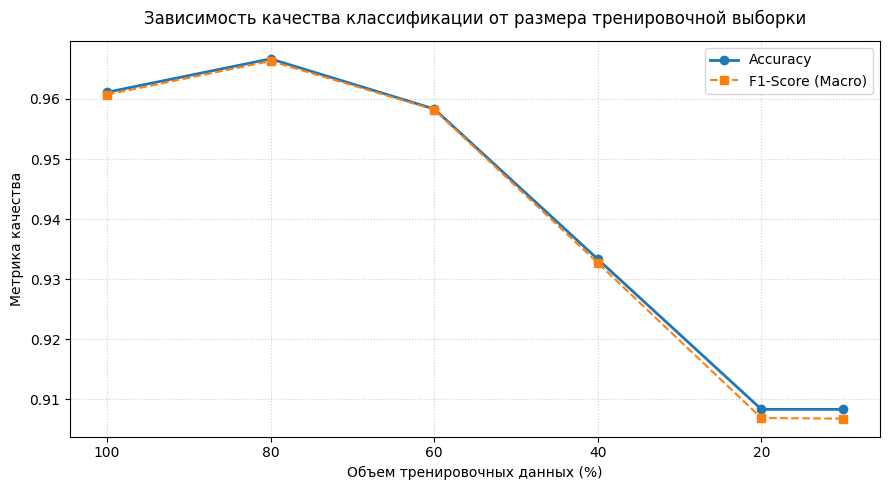

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Загрузка стандартного датасета (набор рукописных цифр)
data = load_digits()
X, y = data.data, data.target

# Разделение на train (80%) и test (20%). Тестовую выборку мы фиксируем!
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Эксперимент: сокращение тренировочного датасета от 100% до 10%
fractions = [1.0, 0.8, 0.6, 0.4, 0.2, 0.1]
accuracies = []
f1_scores = []
train_sizes = []

for frac in fractions:
    if frac == 1.0:
        X_sub, y_sub = X_train_full, y_train_full
    else:
        # Искусственное сокращение с сохранением баланса классов (stratify)
        X_sub, _, y_sub, _ = train_test_split(
            X_train_full, y_train_full, train_size=frac, random_state=42, stratify=y_train_full
        )

    # Обучение модели (Random Forest)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_sub, y_sub)

    # Оценка на фиксированном тестовом наборе
    y_pred = Math = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    _, _, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

    accuracies.append(acc)
    f1_scores.append(f1)
    train_sizes.append(len(X_sub))

    print(f"Размер выборки: {frac*100:.0f}% ({len(X_sub)} объектов) | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")

# 3. Построение графика
plt.figure(figsize=(9, 5))
plt.plot([f*100 for f in fractions], accuracies, marker='o', linewidth=2, color='#1f77b4', label='Accuracy')
plt.plot([f*100 for f in fractions], f1_scores, marker='s', linestyle='--', color='#ff7f0e', label='F1-Score (Macro)')

plt.title('Зависимость качества классификации от размера тренировочной выборки', fontsize=12, pad=12)
plt.xlabel('Объем тренировочных данных (%)', fontsize=10)
plt.ylabel('Метрика качества', fontsize=10)
plt.gca().invert_xaxis()  # Инвертируем ось X (от 100% к 10%)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('dataset_reduction_experiment.png', dpi=300)
plt.show()